# Машинное обучение. Задание 2

## Регрессионный анализ: экстраполяция в задачах прогнозирования временных рядов

Выполнил: Егор Пирогов
НИУ ВШЭ — Пермь, кафедра информационных технологий в бизнесе, 2026

### Набор данных

Используется файл данных из задания 1 — почасовые метеонаблюдения по Перми за
2024 год (Open-Meteo Archive API, реанализ ERA5, 8784 наблюдения). Это
собственный набор в форме временного ряда, а не файл преподавателя — пункт 1
дополнительной части.

### Что делается в работе

| Пункт задания | Раздел |
|---|---|
| 1. Прогноз 20 % значений: ARIMA и k-NN / скользящее среднее | 2, 3 |
| 2. Однопараметрические модели МНК и SVM (SVR) | 4 |
| 3. Модели с двумя параметрами | 5 |
| 4. Графики прогнозов с тренировочной и тестовой выборками | 2—6 |
| 5. Сравнение по MAE и RMSE, выводы | 6, 9 |
| Доп. +1: свой файл данных, Lasso и PLS, метрика R² | 1, 7 |
| Доп. +2: размер обучающей выборки, рекурсивное усложнение моделей | 8 |

Целевая оценка — 11 баллов: 8 за базовую часть, 1 и 2 за обе дополнительные.

### Импорт библиотек и настройка оформления

In [2]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Lasso
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
from statsmodels.tsa.arima.model import ARIMA

# Вспомогательные функции: метрики и рекурсивный прогноз на горизонт.
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from hw_utils import style_axes
from hw2_utils import (
    mae, rmse, r2, metrics_row,
    moving_average_forecast, make_lag_matrix,
    recursive_forecast, recursive_forecast_exog,
)

DATA = Path.cwd().parent / "data" / "raw" / "perm_2024_hourly.csv"
FIG = Path.cwd().parent / "figures"
FIG.mkdir(exist_ok=True)

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["figure.facecolor"] = "white"
sns.set_style("white")

np.random.seed(42)
pd.set_option("display.precision", 3)

# statsmodels предупреждает о сходимости оптимизатора на коротких рядах —
# на результат это не влияет, вывод ячеек не засоряем.
warnings.filterwarnings("ignore")

print("Проверка кириллицы: Пермь, температура −32.5 °C")
print("pandas", pd.__version__, "| numpy", np.__version__)

Проверка кириллицы: Пермь, температура −32.5 °C
pandas 3.0.5 | numpy 2.4.6


---
## Пункт 1. Данные, выбор участка ряда и разбиение на выборки

Прогнозируемый параметр — **температура воздуха** `temperature_2m`.
По условию нужно не менее 100 последовательных значений, разбитых на
тренировочную (80 %) и тестовую (20 %) выборки.

Берём **120 последовательных часовых значений** — ровно пять суток, с 1 по 5
июля 2024 года. Длина выбрана кратной суткам не случайно: у температуры
выраженный суточный цикл, и при некратной длине тестовая выборка захватила бы
неполный период, из-за чего сравнение моделей зависело бы от того, на какую
фазу цикла пришлась граница разбиения.

Разбиение: **96 значений (4 суток) — обучение, 24 значения (1 сутки) —
тест**. Горизонт прогноза равен 24 шагам, то есть прогнозируем на сутки
вперёд, не видя ни одного истинного значения из теста.

In [3]:
df = pd.read_csv(DATA, skiprows=3)
df.columns = ["time", "temp", "humidity", "pressure",
              "wind_speed", "wind_dir", "precip"]
df["time"] = pd.to_datetime(df["time"])
df = df.set_index("time").sort_index()

# Участок ряда: 120 последовательных часов, 01.07.2024 — 05.07.2024.
SEG_START = "2024-07-01 00:00"
N_TOTAL = 120
seg = df.loc[SEG_START:].iloc[:N_TOTAL]

N_TRAIN = int(N_TOTAL * 0.8)   # 96 — четверо суток
N_TEST = N_TOTAL - N_TRAIN     # 24 — сутки, горизонт прогноза
HORIZON = N_TEST

y = seg["temp"].to_numpy(float)
y_train, y_test = y[:N_TRAIN], y[N_TRAIN:]

# Номер шага внутри участка — это и есть независимая переменная x для МНК и SVR.
t = np.arange(N_TOTAL, dtype=float)
t_train, t_test = t[:N_TRAIN], t[N_TRAIN:]

idx_train, idx_test = seg.index[:N_TRAIN], seg.index[N_TRAIN:]

print(f"Участок ряда: {seg.index[0]} — {seg.index[-1]}")
print(f"Всего значений: {N_TOTAL} (требуется не менее 100)")
print(f"Тренировочная выборка: {N_TRAIN} значений ({N_TRAIN / N_TOTAL:.0%}), "
      f"{idx_train[0]} — {idx_train[-1]}")
print(f"Тестовая выборка:      {N_TEST} значений ({N_TEST / N_TOTAL:.0%}), "
      f"{idx_test[0]} — {idx_test[-1]}")
print(f"\nПропусков на участке: {seg['temp'].isna().sum()}")
print(f"Температура: от {y.min():.1f} до {y.max():.1f} °C")
print(f"Среднее и СКО теста: {y_test.mean():.2f} ± {y_test.std(ddof=1):.2f} °C")

Участок ряда: 2024-07-01 00:00:00 — 2024-07-05 23:00:00
Всего значений: 120 (требуется не менее 100)
Тренировочная выборка: 96 значений (80%), 2024-07-01 00:00:00 — 2024-07-04 23:00:00
Тестовая выборка:      24 значений (20%), 2024-07-05 00:00:00 — 2024-07-05 23:00:00

Пропусков на участке: 0
Температура: от 13.5 до 30.8 °C
Среднее и СКО теста: 25.44 ± 3.99 °C


### Почему на этом участке вообще есть что прогнозировать

Прежде чем строить модели, посмотрим на структуру ряда: если бы температура
менялась хаотично, ни одна экстраполяция не дала бы результата лучше среднего.
Автокорреляционная функция показывает, насколько значение ряда связано со своим
значением, отстоящим на *k* шагов назад.

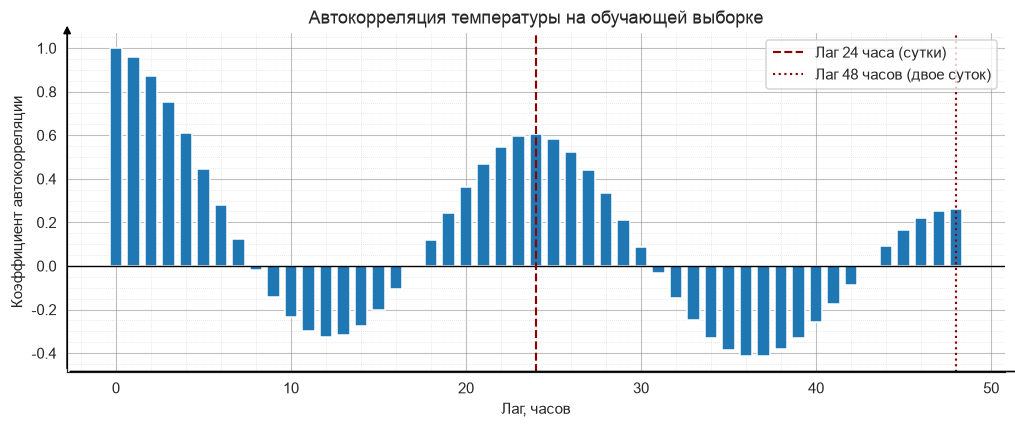

Автокорреляция на лаге  1 ч: 0.959
Автокорреляция на лаге 12 ч: -0.324
Автокорреляция на лаге 24 ч: 0.608
Автокорреляция на лаге 48 ч: 0.263


In [4]:
def acf(series, max_lag):
    # Автокорреляционная функция ряда до лага max_lag включительно.
    s = np.asarray(series, float) - np.mean(series)
    denom = float(np.sum(s * s))
    return np.array([float(np.sum(s[k:] * s[:len(s) - k]) / denom)
                     for k in range(max_lag + 1)])

acf_vals = acf(y_train, 48)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(np.arange(len(acf_vals)), acf_vals, color="tab:blue", width=0.7)
ax.axhline(0, color="black", lw=0.9)
ax.axvline(24, color="darkred", ls="--", lw=1.4, label="Лаг 24 часа (сутки)")
ax.axvline(48, color="darkred", ls=":", lw=1.4, label="Лаг 48 часов (двое суток)")
style_axes(ax, "Лаг, часов", "Коэффициент автокорреляции",
           "Автокорреляция температуры на обучающей выборке")
ax.legend()
fig.savefig(FIG / "hw2_01_acf.png")
plt.show()

print(f"Автокорреляция на лаге  1 ч: {acf_vals[1]:.3f}")
print(f"Автокорреляция на лаге 12 ч: {acf_vals[12]:.3f}")
print(f"Автокорреляция на лаге 24 ч: {acf_vals[24]:.3f}")
print(f"Автокорреляция на лаге 48 ч: {acf_vals[48]:.3f}")

В ряде видны две закономерности, и обе понадобятся дальше.

1. **Высокая автокорреляция на малых лагах** — соседние часы почти не
   различаются. На этом держатся все модели, опирающиеся на ближайшее прошлое.
2. **Локальный максимум на лаге 24 часа** — суточный цикл: температура
   в 14:00 похожа на температуру в 14:00 предыдущих суток. Провал около лага 12
   часов — противофаза «день против ночи».

Суточный цикл — главная особенность этого ряда. Ниже видно, что именно
способность модели его воспроизвести определяет качество прогноза на сутки
вперёд, а вовсе не сложность метода.

---
## Пункт 1а. Модель ARIMA

Модель ARIMA(p, d, q): авторегрессия по p предыдущим значениям, d-кратное
взятие разностей для приведения ряда к стационарному виду и скользящее среднее
порядка q по случайным ошибкам.

Порядок подбираем не наугад: сравним несколько вариантов по информационному
критерию Акаике (AIC) на обучающей выборке. AIC штрафует лишние параметры,
поэтому выбирает модель, которая объясняет ряд, не переусложняясь.

Отдельно проверим модель **с сезонной составляющей периода 24 часа** — ту самую
суточную цикличность, которую показала автокорреляция.

In [5]:
# (p, d, q) и сезонная часть (P, D, Q, s); s = 24 — суточный период.
candidates = [
    ((1, 0, 0), None),
    ((2, 0, 2), None),
    ((2, 1, 2), None),
    ((3, 1, 1), None),
    ((1, 0, 0), (1, 0, 0, 24)),
    ((1, 0, 1), (1, 0, 0, 24)),
    ((2, 0, 0), (1, 0, 0, 24)),
]

rows = []
fitted = {}
for order, seasonal in candidates:
    kwargs = {"seasonal_order": seasonal} if seasonal else {}
    model = ARIMA(y_train, order=order, **kwargs).fit()
    name = f"ARIMA{order}" + (f"×{seasonal}" if seasonal else "")
    fitted[name] = model
    rows.append({"Модель": name, "AIC": model.aic, "Параметров": len(model.params)})

aic_table = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
aic_table

,Модель,AIC,Параметров
0,"ARIMA(2, 0, 0)×(1, 0, 0, 24)",222.419,5
1,"ARIMA(1, 0, 1)×(1, 0, 0, 24)",226.869,5
2,"ARIMA(2, 0, 2)",235.414,6
3,"ARIMA(1, 0, 0)×(1, 0, 0, 24)",239.633,4
4,"ARIMA(3, 1, 1)",239.986,5
5,"ARIMA(2, 1, 2)",241.464,5
6,"ARIMA(1, 0, 0)",307.795,3


Дальше берём две модели: лучшую **несезонную** и лучшую **сезонную**. Сравнение
именно этой пары показывает вклад суточного цикла в отрыве от прочих различий.

In [8]:
best_plain = min((r for r in rows if "×" not in r["Модель"]), key=lambda r: r["AIC"])["Модель"]
best_seas = min((r for r in rows if "×" in r["Модель"]), key=lambda r: r["AIC"])["Модель"]
print("Лучшая несезонная модель:", best_plain)
print("Лучшая сезонная модель:  ", best_seas)

# Прогноз строится на весь горизонт сразу: forecast() продолжает ряд за
# пределы обучающей выборки, не заглядывая в тестовые значения.
pred_arima_plain = np.asarray(fitted[best_plain].forecast(HORIZON), float)
pred_arima_seas = np.asarray(fitted[best_seas].forecast(HORIZON), float)

print(f"\n{best_plain}:")
print("  ", {k: round(v, 3) for k, v in metrics_row(y_test, pred_arima_plain).items()})
print(f"{best_seas}:")
print("  ", {k: round(v, 3) for k, v in metrics_row(y_test, pred_arima_seas).items()})

Лучшая несезонная модель: ARIMA(2, 0, 2)
Лучшая сезонная модель:   ARIMA(2, 0, 0)×(1, 0, 0, 24)

ARIMA(2, 0, 2):
   {'MAE': 4.787, 'RMSE': 6.179, 'R2': -1.508}
ARIMA(2, 0, 0)×(1, 0, 0, 24):
   {'MAE': 1.663, 'RMSE': 1.916, 'R2': 0.759}


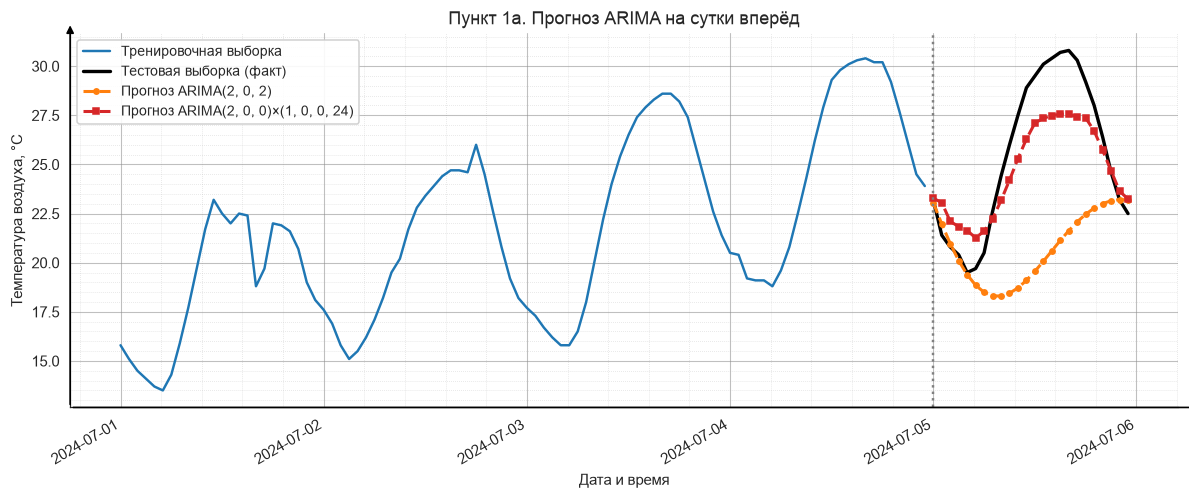

In [9]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(idx_train, y_train, color="tab:blue", lw=1.6, label="Тренировочная выборка")
ax.plot(idx_test, y_test, color="black", lw=2.2, label="Тестовая выборка (факт)")
ax.plot(idx_test, pred_arima_plain, color="tab:orange", lw=2, ls="--",
        marker="o", ms=3.5, label=f"Прогноз {best_plain}")
ax.plot(idx_test, pred_arima_seas, color="tab:red", lw=2, ls="--",
        marker="s", ms=3.5, label=f"Прогноз {best_seas}")
ax.axvline(idx_test[0], color="grey", ls=":", lw=1.6)

style_axes(ax, "Дата и время", "Температура воздуха, °C",
           "Пункт 1а. Прогноз ARIMA на сутки вперёд")
ax.legend(loc="upper left", framealpha=0.9, fontsize=9)
fig.autofmt_xdate()
fig.savefig(FIG / "hw2_02_arima.png")
plt.show()

Разница между двумя кривыми — главный результат этого пункта.

**Несезонная ARIMA прогнозирует почти горизонтальную линию.** Так и должно
быть: авторегрессия по нескольким последним часам «помнит» ряд лишь на
несколько шагов назад, а дальше прогноз сходится к среднему уровню ряда. На
горизонте 24 шага память давно исчерпана, и модель выдаёт константу — суточные
колебания амплитудой более 10 °C она не воспроизводит вовсе.

**Сезонная модель повторяет форму суточного хода**, потому что среди её
регрессоров есть значение ряда сутки назад. Она ошибается в амплитуде, но
угадывает фазу: ночной минимум и дневной максимум оказываются примерно там, где
они есть на самом деле.

---
## Пункт 1б. k-NN / скользящее среднее

Оценка равна среднему k предшествующих значений ряда,

$$y_i = \frac{1}{k}\sum_{j=1}^{k} y_{i-j}.$$

Поскольку прогноз строится на 24 шага вперёд, работает принцип прогноза на
горизонт планирования: собственный прогноз становится «реальным» значением для
следующего шага. Это реализовано в функции `moving_average_forecast` модуля
`hw2_utils.py`.

Параметр k подбираем по скользящей проверке **внутри обучающей выборки** —
последние 24 часа обучения временно играют роль проверочных. Тестовая выборка
при подборе не используется: иначе мы бы подстроили параметр под ответ.

In [10]:
# Подбор k: обучение делим ещё раз, последние 24 часа — проверочная часть.
val_size = 24
y_fit, y_val = y_train[:-val_size], y_train[-val_size:]

k_grid = [1, 2, 3, 4, 6, 8, 12, 18, 24]
val_rows = []
for k in k_grid:
    pred_val = moving_average_forecast(y_fit, val_size, k)
    val_rows.append({"k": k, "MAE на проверке": mae(y_val, pred_val),
                     "RMSE на проверке": rmse(y_val, pred_val)})

val_table = pd.DataFrame(val_rows)
K_BEST = int(val_table.loc[val_table["MAE на проверке"].idxmin(), "k"])
print(f"Выбранное число соседей: k = {K_BEST}")
val_table

Выбранное число соседей: k = 24


,k,MAE на проверке,RMSE на проверке
0,1,4.746,5.645
1,2,4.618,5.400
2,3,4.473,5.141
3,4,4.345,4.904
4,6,4.140,4.579
5,8,4.056,4.476
6,12,4.083,4.580
7,18,4.066,4.531
8,24,3.512,3.902


Скользящее среднее, k = 24:
   {'MAE': 3.167, 'RMSE': 3.618, 'R2': 0.14}


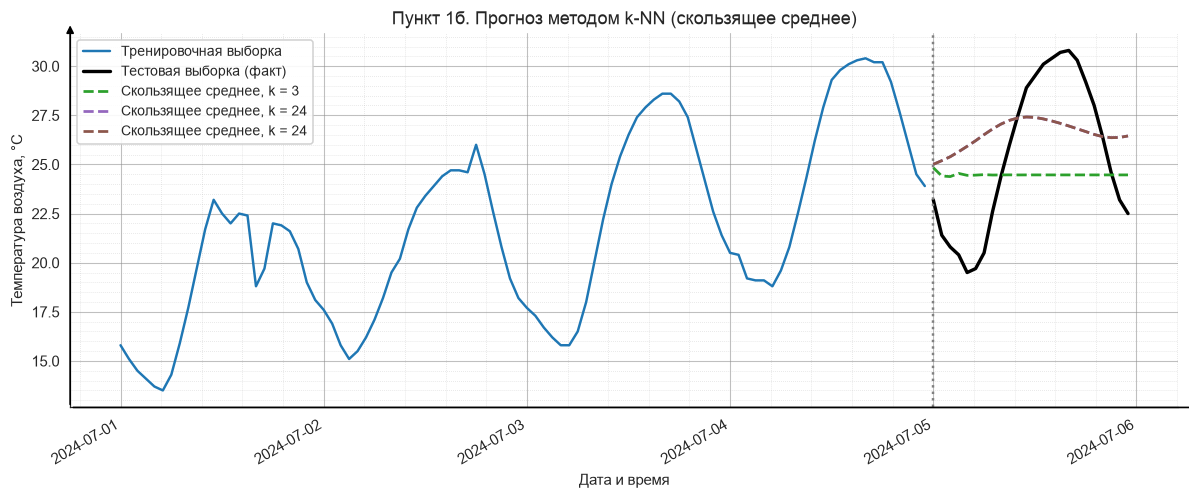

In [11]:
pred_knn = moving_average_forecast(y_train, HORIZON, K_BEST)
print(f"Скользящее среднее, k = {K_BEST}:")
print("  ", {k: round(v, 3) for k, v in metrics_row(y_test, pred_knn).items()})

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(idx_train, y_train, color="tab:blue", lw=1.6, label="Тренировочная выборка")
ax.plot(idx_test, y_test, color="black", lw=2.2, label="Тестовая выборка (факт)")

# Показываем несколько k сразу: видно, что выбор k почти не спасает метод.
for k, color in zip([3, K_BEST, 24], ["tab:green", "tab:purple", "tab:brown"]):
    ax.plot(idx_test, moving_average_forecast(y_train, HORIZON, k),
            lw=1.8, ls="--", color=color, label=f"Скользящее среднее, k = {k}")

ax.axvline(idx_test[0], color="grey", ls=":", lw=1.6)
style_axes(ax, "Дата и время", "Температура воздуха, °C",
           "Пункт 1б. Прогноз методом k-NN (скользящее среднее)")
ax.legend(loc="upper left", framealpha=0.9, fontsize=9)
fig.autofmt_xdate()
fig.savefig(FIG / "hw2_03_knn.png")
plt.show()

Все кривые скользящего среднего за несколько шагов вырождаются в горизонтальную
линию, и величина k на это не влияет — меняется лишь уровень, на котором
прогноз застывает.

Причина в самой рекурсивной схеме. На первом шаге усредняются настоящие
значения, на втором — k−1 настоящее и один собственный прогноз, и так далее;
через k шагов в окне не остаётся ни одного реального наблюдения, среднее
начинает усредняться само с собой и перестаёт меняться. Метод по построению не
способен к экстраполяции циклического поведения: он умеет только сглаживать
ближайшее прошлое.

Отсюда практический вывод: на горизонте в одни сутки скользящее среднее — не
столько рабочая модель, сколько **базовый уровень**, относительно которого
оценивают остальные.

---
## Пункт 2. Однопараметрические модели: МНК и SVM (SVR)

По условию МНК строится в виде $y = c_0 + c_1 x$. В роли независимой переменной
$x$ выступает **номер шага времени** — так задача прогнозирования следующих
значений по предыдущим превращается в задачу экстраполяции за границу
обучающего интервала: точка прогноза лежит вне отрезка $[a, b]$.

Коэффициенты МНК считаем двумя способами — через `LinearRegression` и напрямую
по формуле с псевдообратной матрицей $c = (A^TA)^{-1}A^Ty$, чтобы убедиться,
что библиотека делает ровно то, что описано в методичке.

In [12]:
X_train_1 = t_train.reshape(-1, 1)
X_test_1 = t_test.reshape(-1, 1)

ols_1 = LinearRegression().fit(X_train_1, y_train)
pred_ols_1 = ols_1.predict(X_test_1)

# Та же задача вручную: матрица A из базисных функций 1 и x.
A = np.c_[np.ones(N_TRAIN), t_train]
c_manual = np.linalg.inv(A.T @ A) @ A.T @ y_train

print(f"МНК через LinearRegression: c0 = {ols_1.intercept_:.4f}, c1 = {ols_1.coef_[0]:.4f}")
print(f"МНК через (A^T A)^-1 A^T y: c0 = {c_manual[0]:.4f}, c1 = {c_manual[1]:.4f}")
print(f"Совпадение коэффициентов: {np.allclose([ols_1.intercept_, ols_1.coef_[0]], c_manual)}")
print(f"\nУравнение модели: y = {ols_1.intercept_:.3f} + {ols_1.coef_[0]:.4f}·x")
print(f"Смысл наклона: {ols_1.coef_[0] * 24:.2f} °C за сутки")
print("\nМНК:", {k: round(v, 3) for k, v in metrics_row(y_test, pred_ols_1).items()})

МНК через LinearRegression: c0 = 16.6925, c1 = 0.1062
МНК через (A^T A)^-1 A^T y: c0 = 16.6925, c1 = 0.1062
Совпадение коэффициентов: True

Уравнение модели: y = 16.693 + 0.1062·x
Смысл наклона: 2.55 °C за сутки

МНК: {'MAE': 3.707, 'RMSE': 4.445, 'R2': -0.298}


### SVR на том же единственном параметре

SVR ищет функцию, вокруг которой построена ε-полоса: точки внутри
полосы штрафа не получают вовсе, а за её пределами штраф растёт линейно с весом
C. Признак и отклик масштабируем — метод чувствителен к масштабу, поскольку
ширина ε задаётся в единицах отклика.

Гиперпараметры C и ε подбираем по той же внутренней проверке, что и k выше:
последние 24 часа обучающей выборки, тестовые данные не участвуют.

In [13]:
def fit_svr(x_tr, y_tr, C, eps):
    # Обучение SVR со стандартизацией признаков и отклика.
    sx = StandardScaler().fit(x_tr)
    sy = StandardScaler().fit(y_tr.reshape(-1, 1))
    model = SVR(kernel="rbf", C=C, epsilon=eps)
    model.fit(sx.transform(x_tr), sy.transform(y_tr.reshape(-1, 1)).ravel())

    def predict(x_new):
        raw = model.predict(sx.transform(x_new)).reshape(-1, 1)
        return sy.inverse_transform(raw).ravel()

    return model, predict


# Подбор C и epsilon на внутренней проверочной части обучающей выборки.
x_fit, x_val = t_train[:-val_size].reshape(-1, 1), t_train[-val_size:].reshape(-1, 1)
svr_rows = []
for C in [0.1, 1, 10, 100]:
    for eps in [0.05, 0.1, 0.5]:
        _, pr = fit_svr(x_fit, y_fit, C, eps)
        svr_rows.append({"C": C, "epsilon": eps, "MAE на проверке": mae(y_val, pr(x_val))})

svr_table = pd.DataFrame(svr_rows).sort_values("MAE на проверке").reset_index(drop=True)
C_BEST = float(svr_table.loc[0, "C"])
EPS_BEST = float(svr_table.loc[0, "epsilon"])
print(f"Выбраны параметры: C = {C_BEST}, epsilon = {EPS_BEST}")
# Показываем всю сетку: важен не только оптимум, но и поведение при росте C.
svr_table

Выбраны параметры: C = 0.1, epsilon = 0.5


,C,epsilon,MAE на проверке
0,0.1,0.50,4.935
1,0.1,0.10,5.005
2,0.1,0.05,5.050
3,1.0,0.50,5.704
4,1.0,0.10,5.941
5,1.0,0.05,5.945
6,10.0,0.50,12.473
7,10.0,0.05,16.295
8,10.0,0.10,16.499
9,100.0,0.50,21.092


Опорных векторов: 68 из 96 обучающих точек (71%)
SVR: {'MAE': 3.932, 'RMSE': 4.502, 'R2': -0.331}


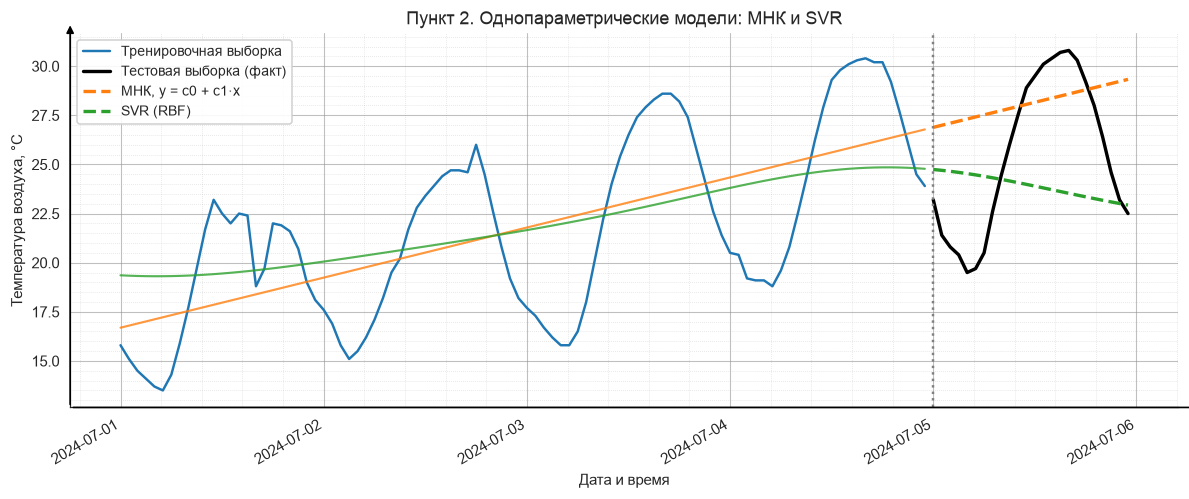

In [14]:
svr_model_1, svr_predict_1 = fit_svr(X_train_1, y_train, C_BEST, EPS_BEST)
pred_svr_1 = svr_predict_1(X_test_1)

print(f"Опорных векторов: {len(svr_model_1.support_)} из {N_TRAIN} обучающих точек "
      f"({len(svr_model_1.support_) / N_TRAIN:.0%})")
print("SVR:", {k: round(v, 3) for k, v in metrics_row(y_test, pred_svr_1).items()})

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(idx_train, y_train, color="tab:blue", lw=1.6, label="Тренировочная выборка")
ax.plot(idx_test, y_test, color="black", lw=2.2, label="Тестовая выборка (факт)")

# Обе модели показываем и на обучении, и на прогнозе: видно, что они делают
# внутри интервала и что происходит при выходе за его границу.
ax.plot(idx_train, ols_1.predict(X_train_1), color="tab:orange", lw=1.4, alpha=0.8)
ax.plot(idx_test, pred_ols_1, color="tab:orange", lw=2.2, ls="--", label="МНК, y = c0 + c1·x")
ax.plot(idx_train, svr_predict_1(X_train_1), color="tab:green", lw=1.4, alpha=0.8)
ax.plot(idx_test, pred_svr_1, color="tab:green", lw=2.2, ls="--", label="SVR (RBF)")

ax.axvline(idx_test[0], color="grey", ls=":", lw=1.6)
style_axes(ax, "Дата и время", "Температура воздуха, °C",
           "Пункт 2. Однопараметрические модели: МНК и SVR")
ax.legend(loc="upper left", framealpha=0.9, fontsize=9)
fig.autofmt_xdate()
fig.savefig(FIG / "hw2_04_ols_svr_1p.png")
plt.show()

Графики показывают разницу между интерполяцией и экстраполяцией предельно
наглядно.

**МНК** даёт прямую — единственное, что он может выразить в форме
$y = c_0 + c_1x$. На обучающем участке она проходит по середине колебаний, а за
его границей продолжает медленный подъём, никак не отражая суточный ход. Модель
недообучена: она слишком проста для структуры данных.

**SVR с RBF-ядром** ведёт себя противоположным образом: внутри обучающего
интервала он повторяет колебания заметно точнее прямой, но за его границей
быстро уходит к константе. Так устроено само ядро — оно измеряет близость
новой точки к опорным векторам, а точки прогноза лежат от всех обучающих
далеко по оси времени, поэтому все ядровые функции затухают и остаётся
свободный член.

Общий вывод пункта: **время как единственный регрессор не несёт информации о
цикле**. Обе модели видят лишь монотонный номер шага, и ни одна не может знать,
что через 24 шага картина повторится.

---
## Пункт 3. Модели с двумя параметрами

Добавляем второй параметр из того же файла данных. По условию для МНК
используется $y = c_0 + c_1x_1 + c_2x_2$.

В качестве $x_2$ берём **относительную влажность**: в задании 1 показано, что
внутри суток она связана с температурой сильной обратной зависимостью
(тёплый воздух удерживает больше водяного пара, поэтому дневной нагрев снижает
относительную влажность). Проверим эту связь на рабочем участке.

Важная деталь постановки. Влажность в будущем нам **неизвестна** — это такой же
прогнозируемый параметр, как и температура. Поэтому при прогнозе на горизонт
планирования делаем прогноз для каждого из параметров модели: сначала строим
прогноз второго параметра, и уже его подаём в модель.
Подставить истинные значения влажности из теста было бы заглядыванием в ответ.

Корреляция температуры и влажности на обучающей выборке: r = -0.855
Качество прогноза влажности: MAE = 6.31 %, RMSE = 7.82 %


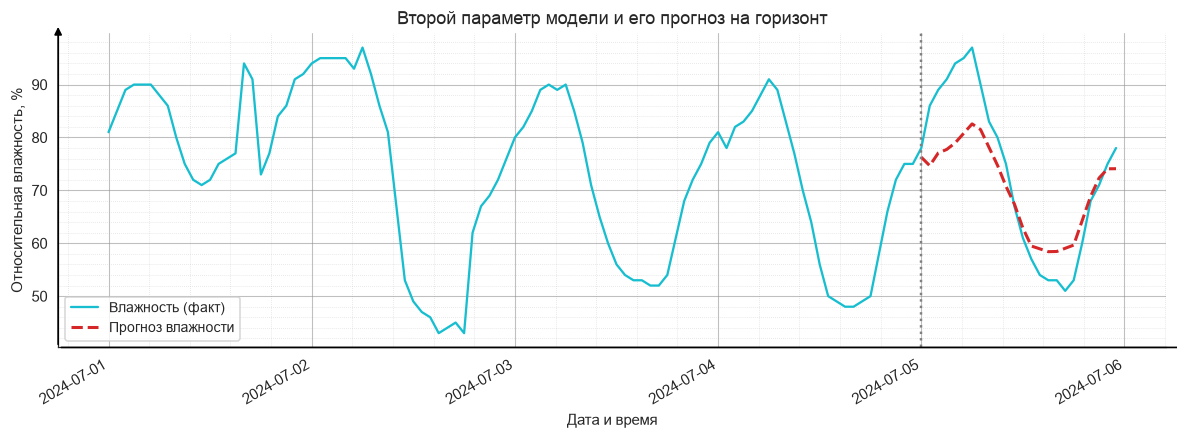

In [15]:
humidity = seg["humidity"].to_numpy(float)
hum_train, hum_test = humidity[:N_TRAIN], humidity[N_TRAIN:]

corr_all = np.corrcoef(y_train, hum_train)[0, 1]
print(f"Корреляция температуры и влажности на обучающей выборке: r = {corr_all:.3f}")

# Прогноз влажности на горизонт — той же сезонной моделью, что и для температуры.
hum_model = ARIMA(hum_train, order=(1, 0, 0), seasonal_order=(1, 0, 0, 24)).fit()
hum_future = np.asarray(hum_model.forecast(HORIZON), float)
print(f"Качество прогноза влажности: MAE = {mae(hum_test, hum_future):.2f} %, "
      f"RMSE = {rmse(hum_test, hum_future):.2f} %")

fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(seg.index, humidity, color="tab:cyan", lw=1.5, label="Влажность (факт)")
ax.plot(idx_test, hum_future, color="tab:red", lw=2, ls="--", label="Прогноз влажности")
ax.axvline(idx_test[0], color="grey", ls=":", lw=1.6)
style_axes(ax, "Дата и время", "Относительная влажность, %",
           "Второй параметр модели и его прогноз на горизонт")
ax.legend(loc="lower left", fontsize=9)
fig.autofmt_xdate()
fig.savefig(FIG / "hw2_05_humidity.png")
plt.show()

In [16]:
# Матрица двух параметров: x1 — номер шага, x2 — влажность.
X_train_2 = np.c_[t_train, hum_train]
X_test_2 = np.c_[t_test, hum_future]     # во второй колонке — ПРОГНОЗ, не факт

ols_2 = LinearRegression().fit(X_train_2, y_train)
pred_ols_2 = ols_2.predict(X_test_2)

print(f"Уравнение: y = {ols_2.intercept_:.3f} + {ols_2.coef_[0]:.4f}·x1 "
      f"+ ({ols_2.coef_[1]:.4f})·x2")
print("МНК, 2 параметра:", {k: round(v, 3) for k, v in metrics_row(y_test, pred_ols_2).items()})

svr_model_2, svr_predict_2 = fit_svr(X_train_2, y_train, C_BEST, EPS_BEST)
pred_svr_2 = svr_predict_2(X_test_2)
print("SVR, 2 параметра: ", {k: round(v, 3) for k, v in metrics_row(y_test, pred_svr_2).items()})

Уравнение: y = 34.404 + 0.0586·x1 + (-0.2103)·x2
МНК, 2 параметра: {'MAE': 1.972, 'RMSE': 2.252, 'R2': 0.667}
SVR, 2 параметра:  {'MAE': 3.02, 'RMSE': 3.528, 'R2': 0.182}


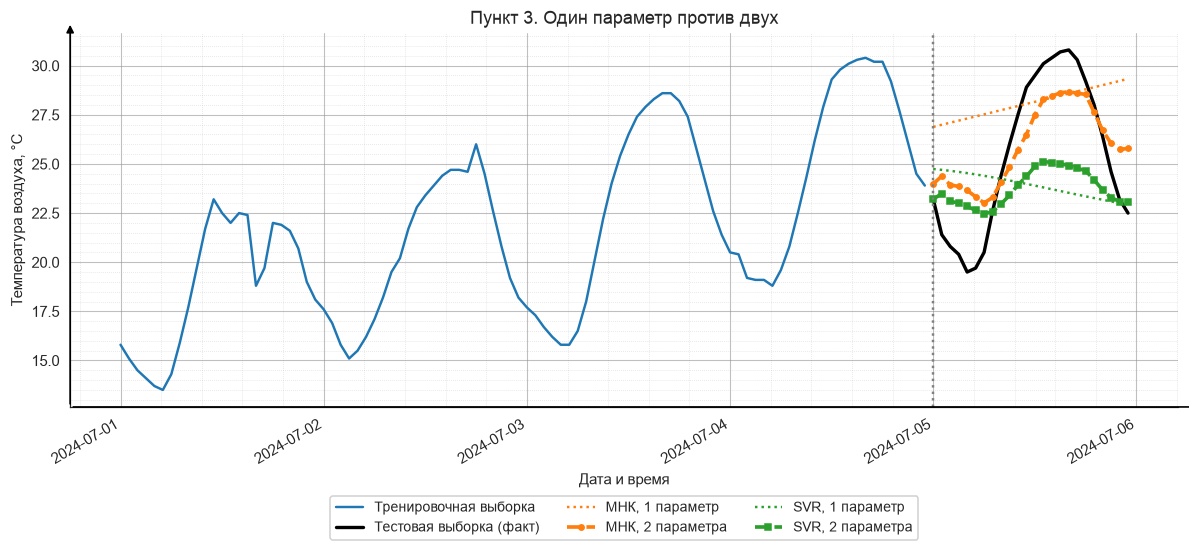

In [17]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(idx_train, y_train, color="tab:blue", lw=1.6, label="Тренировочная выборка")
ax.plot(idx_test, y_test, color="black", lw=2.2, label="Тестовая выборка (факт)")
ax.plot(idx_test, pred_ols_1, color="tab:orange", lw=1.6, ls=":", label="МНК, 1 параметр")
ax.plot(idx_test, pred_ols_2, color="tab:orange", lw=2.4, ls="--",
        marker="o", ms=3.5, label="МНК, 2 параметра")
ax.plot(idx_test, pred_svr_1, color="tab:green", lw=1.6, ls=":", label="SVR, 1 параметр")
ax.plot(idx_test, pred_svr_2, color="tab:green", lw=2.4, ls="--",
        marker="s", ms=3.5, label="SVR, 2 параметра")
ax.axvline(idx_test[0], color="grey", ls=":", lw=1.6)
style_axes(ax, "Дата и время", "Температура воздуха, °C",
           "Пункт 3. Один параметр против двух")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), framealpha=0.9,
          fontsize=9, ncol=3)
fig.autofmt_xdate()
fig.savefig(FIG / "hw2_06_two_params.png")
plt.show()

Добавление второго параметра меняет качество принципиально, и причина не в том,
что «параметров стало больше».

Влажность сама колеблется с суточным периодом и находится с температурой в
противофазе. Подав её в модель, мы дали линейной функции доступ к информации о
фазе цикла, которой у номера шага не было: коэффициент при влажности
отрицателен, поэтому ночной рост влажности модель пересчитывает в падение
температуры. Прямая превращается в кривую нужной формы, хотя сама модель
осталась линейной по параметрам.

Существенно, что улучшение получено **без заглядывания в ответ**: во вторую
колонку матрицы подставлен прогноз влажности, который и сам содержит ошибку.
Часть этой ошибки переходит в прогноз температуры — это неизбежная плата за
многопараметрическую схему на горизонте больше одного шага.

---
## Пункты 4—5. Сводный график и сравнение по метрикам

Собираем прогнозы всех моделей базовой части на одном графике поверх
тренировочной и тестовой выборок, после чего сравниваем их по MAE и RMSE.

Обе метрики измеряются в градусах Цельсия, то есть читаются напрямую. Разница
между ними содержательна: MAE — средняя величина промаха, RMSE сильнее
штрафует отдельные крупные ошибки. Если RMSE заметно больше MAE, значит
ошибка распределена неравномерно и есть выбросы.

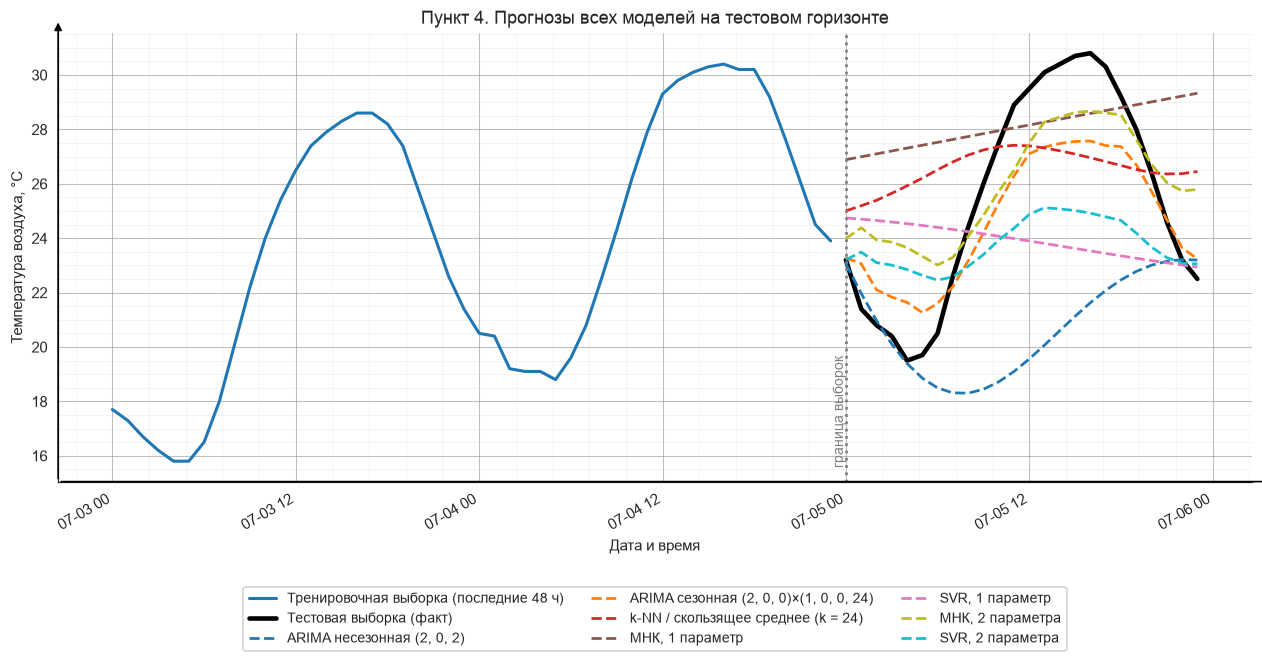

In [18]:
predictions = {
    f"ARIMA несезонная {best_plain.replace('ARIMA', '')}": pred_arima_plain,
    f"ARIMA сезонная {best_seas.replace('ARIMA', '')}": pred_arima_seas,
    f"k-NN / скользящее среднее (k = {K_BEST})": pred_knn,
    "МНК, 1 параметр": pred_ols_1,
    "SVR, 1 параметр": pred_svr_1,
    "МНК, 2 параметра": pred_ols_2,
    "SVR, 2 параметра": pred_svr_2,
}

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(idx_train[-48:], y_train[-48:], color="tab:blue", lw=2,
        label="Тренировочная выборка (последние 48 ч)")
ax.plot(idx_test, y_test, color="black", lw=3, label="Тестовая выборка (факт)")

colors = plt.cm.tab10(np.linspace(0, 1, len(predictions)))
for (name, pred), color in zip(predictions.items(), colors):
    ax.plot(idx_test, pred, lw=1.8, ls="--", color=color, label=name)

ax.axvline(idx_test[0], color="grey", ls=":", lw=1.8)
ax.annotate("граница выборок", xy=(idx_test[0], ax.get_ylim()[0] + 0.5),
            fontsize=9, color="grey", rotation=90, va="bottom", ha="right")
style_axes(ax, "Дата и время", "Температура воздуха, °C",
           "Пункт 4. Прогнозы всех моделей на тестовом горизонте")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), framealpha=0.92,
          fontsize=9, ncol=3)
fig.autofmt_xdate()
fig.savefig(FIG / "hw2_07_all_models.png")
plt.show()

In [19]:
# Опорный уровень для сравнения: прогноз-константа средним обучающей выборки.
pred_naive = np.full(HORIZON, y_train.mean())

table = pd.DataFrame(
    [{"Модель": "Константа (среднее обучения)", **metrics_row(y_test, pred_naive)}]
    + [{"Модель": name, **metrics_row(y_test, pred)} for name, pred in predictions.items()]
).sort_values("MAE").reset_index(drop=True)
table.index += 1

print("Сравнение моделей на тестовой выборке (24 часа):")
table.round(3)

Сравнение моделей на тестовой выборке (24 часа):


,Модель,MAE,RMSE,R2
1,"ARIMA сезонная (2, 0, 0)×(1, 0, 0, 24)",1.663,1.916,0.759
2,"МНК, 2 параметра",1.972,2.252,0.667
3,"SVR, 2 параметра",3.020,3.528,0.182
4,k-NN / скользящее среднее (k = 24),3.167,3.618,0.140
5,"МНК, 1 параметр",3.707,4.445,-0.298
6,"SVR, 1 параметр",3.932,4.502,-0.331
7,Константа (среднее обучения),4.382,5.381,-0.902
8,"ARIMA несезонная (2, 0, 2)",4.787,6.179,-1.508


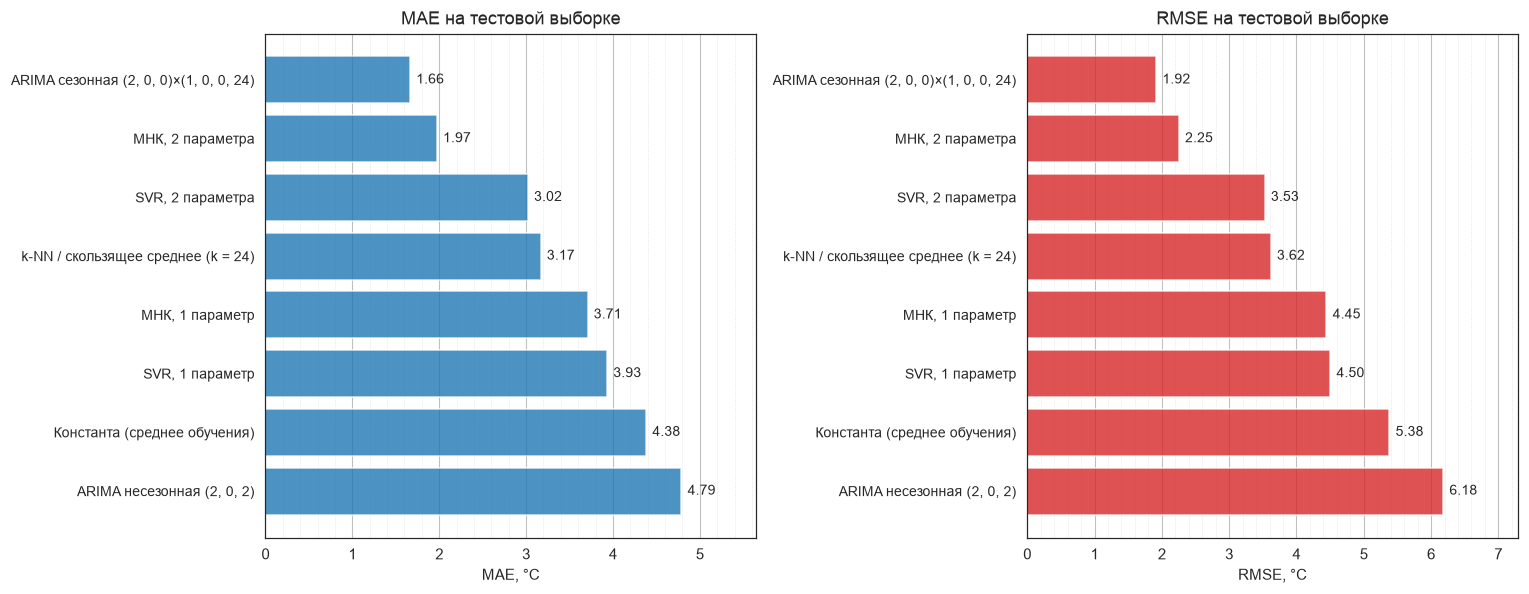

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

order = table.sort_values("MAE", ascending=True)["Модель"].tolist()
for ax, metric, color in zip(axes, ["MAE", "RMSE"], ["tab:blue", "tab:red"]):
    vals = [table.loc[table["Модель"] == m, metric].iloc[0] for m in order]
    bars = ax.barh(range(len(order)), vals, color=color, alpha=0.8)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=9)
    ax.invert_yaxis()
    for bar, v in zip(bars, vals):
        ax.text(v + max(vals) * 0.015, bar.get_y() + bar.get_height() / 2,
                f"{v:.2f}", va="center", fontsize=9)
    style_axes(ax, f"{metric}, °C", "", f"{metric} на тестовой выборке",
               grid_axis="x", arrows=False)
    ax.set_xlim(0, max(vals) * 1.18)

fig.tight_layout()
fig.savefig(FIG / "hw2_08_metrics.png")
plt.show()

### Что показывает сравнение

Модели отчётливо делятся на две группы, и граница проходит не по сложности
метода, а по одному признаку: **имеет ли модель доступ к информации о суточном
цикле**.

В верхней части таблицы — сезонная ARIMA и двухпараметрические модели. Первая
получает эту информацию из значения ряда сутки назад, вторые — из влажности,
которая колеблется синхронно с температурой.

В нижней части — несезонная ARIMA, скользящее среднее и однопараметрические
МНК и SVR. Все они на горизонте 24 шага выдают что-то близкое к прямой линии и
проигрывают либо почти не выигрывают у простейшего прогноза-константы. Заметим,
что среди них есть и «сложный» SVR с нелинейным ядром, и «простой» МНК: сама по
себе сложность метода не помогла.

Сравнение MAE и RMSE добавляет деталь: у моделей, застывающих на константе,
RMSE заметно превышает MAE. Значит их ошибка неравномерна — в момент дневного
максимума и ночного минимума промах максимален, а при переходе кривой через
средний уровень модель случайно оказывается права.

---
## Дополнительная часть, +1 балл. Lasso, PLS и метрика R²

Строим многопараметрические модели методами **Lasso** и **PLS** и добавляем к
сравнению коэффициент детерминации $R^2$.

Про интерпретацию $R^2$ на тестовой выборке важно сказать заранее. Величина
$R^2 = 1 - SS_{res}/SS_{tot}$ сравнивает модель со средним значением **того
ряда, на котором она измеряется**. Поэтому $R^2 < 0$ на тесте — не ошибка
расчёта, а содержательный результат: модель предсказывает хуже, чем
горизонтальная линия на уровне среднего тестовых суток.

Набор регрессоров расширяем до пяти: номер шага, влажность, давление и пара
гармоник суточного периода $\sin(2\pi t/24)$, $\cos(2\pi t/24)$. Гармоники —
стандартный способ дать линейной модели явную информацию о фазе цикла. Значения
влажности и давления на горизонте, как и раньше, берём прогнозные.

In [21]:
pressure = seg["pressure"].to_numpy(float)
pres_train, pres_test = pressure[:N_TRAIN], pressure[N_TRAIN:]

pres_model = ARIMA(pres_train, order=(1, 0, 0), seasonal_order=(1, 0, 0, 24)).fit()
pres_future = np.asarray(pres_model.forecast(HORIZON), float)
print(f"Прогноз давления: MAE = {mae(pres_test, pres_future):.2f} гПа")


def design(t_vals, hum_vals, pres_vals):
    # Матрица пяти регрессоров: время, влажность, давление, две гармоники суток.
    return np.c_[t_vals, hum_vals, pres_vals,
                 np.sin(2 * np.pi * t_vals / 24), np.cos(2 * np.pi * t_vals / 24)]


FEATURES = ["время", "влажность", "давление", "sin(2πt/24)", "cos(2πt/24)"]
F_train = design(t_train, hum_train, pres_train)
F_test = design(t_test, hum_future, pres_future)   # экзогенные — прогнозные

# Lasso и PLS чувствительны к масштабу признаков: давление ~1000 гПа заглушило бы
# гармоники в диапазоне [-1, 1]. Масштаб настраивается только по обучению.
scaler = StandardScaler().fit(F_train)
Fs_train, Fs_test = scaler.transform(F_train), scaler.transform(F_test)

print(f"Размер матрицы регрессоров: {F_train.shape}")

Прогноз давления: MAE = 0.65 гПа
Размер матрицы регрессоров: (96, 5)


In [22]:
# Подбор alpha и числа компонент — снова по внутренней проверке.
Fs_fit, Fs_val = Fs_train[:-val_size], Fs_train[-val_size:]

lasso_rows = []
for alpha in [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 1.0]:
    m = Lasso(alpha=alpha, max_iter=50000).fit(Fs_fit, y_fit)
    lasso_rows.append({"alpha": alpha, "MAE на проверке": mae(y_val, m.predict(Fs_val)),
                       "Ненулевых коэффициентов": int(np.sum(m.coef_ != 0))})
lasso_table = pd.DataFrame(lasso_rows)
ALPHA_BEST = float(lasso_table.loc[lasso_table["MAE на проверке"].idxmin(), "alpha"])

pls_rows = []
for nc in range(1, len(FEATURES) + 1):
    m = PLSRegression(n_components=nc).fit(Fs_fit, y_fit)
    pls_rows.append({"Компонент": nc,
                     "MAE на проверке": mae(y_val, np.ravel(m.predict(Fs_val)))})
pls_table = pd.DataFrame(pls_rows)
NC_BEST = int(pls_table.loc[pls_table["MAE на проверке"].idxmin(), "Компонент"])

print(f"Lasso: выбрано alpha = {ALPHA_BEST}")
print(f"PLS:   выбрано число компонент = {NC_BEST}")
display(lasso_table.round(3))
display(pls_table.round(3))

Lasso: выбрано alpha = 0.001
PLS:   выбрано число компонент = 5


,alpha,MAE на проверке,Ненулевых коэффициентов
0,0.001,0.666,5
1,0.010,0.743,5
2,0.050,1.040,4
3,0.100,1.187,4
4,0.300,1.785,4
5,0.500,2.409,4
6,1.000,3.625,3


,Компонент,MAE на проверке
0,1,1.369
1,2,0.990
2,3,0.783
3,4,0.748
4,5,0.657


In [23]:
ols_multi = LinearRegression().fit(F_train, y_train)
pred_ols_multi = ols_multi.predict(F_test)

lasso = Lasso(alpha=ALPHA_BEST, max_iter=50000).fit(Fs_train, y_train)
pred_lasso = lasso.predict(Fs_test)

pls = PLSRegression(n_components=NC_BEST).fit(Fs_train, y_train)
pred_pls = np.ravel(pls.predict(Fs_test))

print("Коэффициенты Lasso (на стандартизованных признаках):")
for name, coef in zip(FEATURES, lasso.coef_):
    mark = "  — обнулён" if coef == 0 else ""
    print(f"  {name:14s} {coef:8.3f}{mark}")

print("\nВеса первой компоненты PLS:")
for name, w in zip(FEATURES, np.ravel(pls.x_weights_[:, 0])):
    print(f"  {name:14s} {w:8.3f}")

Коэффициенты Lasso (на стандартизованных признаках):
  время             1.321
  влажность        -0.664
  давление          0.920
  sin(2πt/24)      -2.302
  cos(2πt/24)      -1.837

Веса первой компоненты PLS:
  время            -0.430
  влажность         0.577
  давление         -0.411
  sin(2πt/24)       0.444
  cos(2πt/24)       0.340


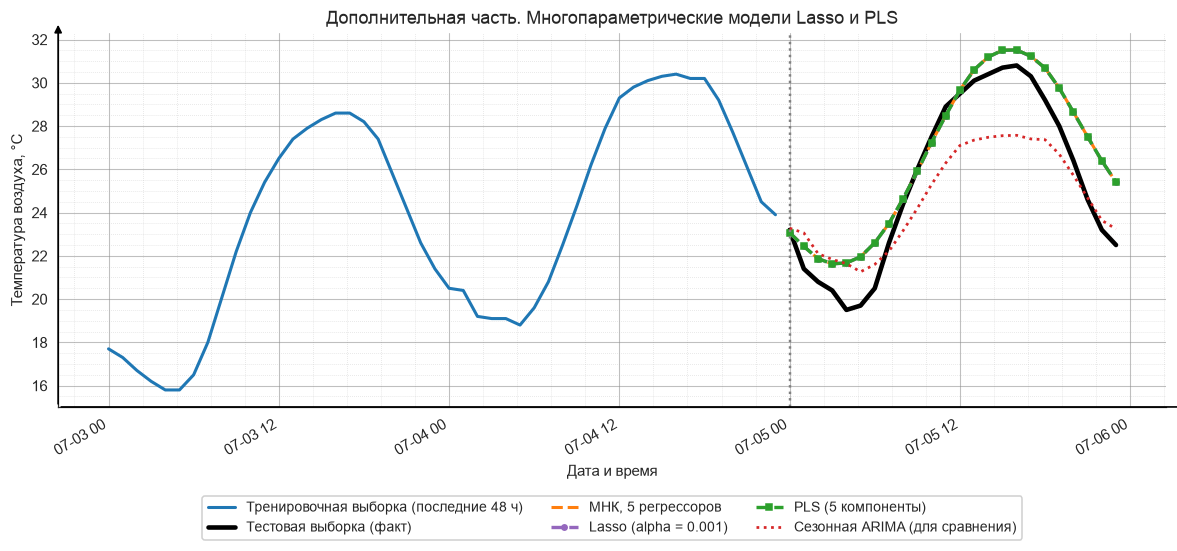

In [24]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(idx_train[-48:], y_train[-48:], color="tab:blue", lw=2,
        label="Тренировочная выборка (последние 48 ч)")
ax.plot(idx_test, y_test, color="black", lw=3, label="Тестовая выборка (факт)")
ax.plot(idx_test, pred_ols_multi, color="tab:orange", lw=2, ls="--",
        label="МНК, 5 регрессоров")
ax.plot(idx_test, pred_lasso, color="tab:purple", lw=2.2, ls="--",
        marker="o", ms=3.5, label=f"Lasso (alpha = {ALPHA_BEST})")
ax.plot(idx_test, pred_pls, color="tab:green", lw=2.2, ls="--",
        marker="s", ms=3.5, label=f"PLS ({NC_BEST} компоненты)")
ax.plot(idx_test, pred_arima_seas, color="tab:red", lw=1.8, ls=":",
        label="Сезонная ARIMA (для сравнения)")
ax.axvline(idx_test[0], color="grey", ls=":", lw=1.6)
style_axes(ax, "Дата и время", "Температура воздуха, °C",
           "Дополнительная часть. Многопараметрические модели Lasso и PLS")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), framealpha=0.92,
          fontsize=9, ncol=3)
fig.autofmt_xdate()
fig.savefig(FIG / "hw2_09_lasso_pls.png")
plt.show()

In [22]:
full_predictions = dict(predictions)
full_predictions["МНК, 5 регрессоров"] = pred_ols_multi
full_predictions[f"Lasso (alpha = {ALPHA_BEST})"] = pred_lasso
full_predictions[f"PLS ({NC_BEST} комп.)"] = pred_pls

full_table = pd.DataFrame(
    [{"Модель": "Константа (среднее обучения)", **metrics_row(y_test, pred_naive)}]
    + [{"Модель": n, **metrics_row(y_test, p)} for n, p in full_predictions.items()]
).sort_values("MAE").reset_index(drop=True)
full_table.index += 1

print("Полное сравнение, включая дополнительную часть (MAE и RMSE в °C):")
full_table.round(3)

Полное сравнение, включая дополнительную часть (MAE и RMSE в °C):


,Модель,MAE,RMSE,R2
1,Lasso (alpha = 0.001),1.262,1.572,0.838
2,"МНК, 5 регрессоров",1.263,1.574,0.837
3,PLS (5 комп.),1.263,1.574,0.837
4,"ARIMA сезонная (2, 0, 0)×(1, 0, 0, 24)",1.663,1.916,0.759
5,"МНК, 2 параметра",1.972,2.252,0.667
6,"SVR, 2 параметра",3.020,3.528,0.182
7,k-NN / скользящее среднее (k = 24),3.167,3.618,0.140
8,"МНК, 1 параметр",3.707,4.445,-0.298
9,"SVR, 1 параметр",3.932,4.502,-0.331
10,Константа (среднее обучения),4.382,5.381,-0.902


### Выводы дополнительной части

**Lasso** с подобранным alpha сохранил все пять регрессоров и дал результат,
практически совпадающий с обычным МНК: при малом alpha $L_1$-штраф почти не
ограничивает коэффициенты, и модель вырождается в МНК. В таблице подбора видно
продолжение: с ростом alpha штраф начинает обнулять признаки, и как только под
нож попадает полезный регрессор, ошибка растёт.

То, что отбор признаков не понадобился, — тоже результат: все пять регрессоров
несут полезную информацию, лишних среди них нет. Lasso ценен там, где признаков
много и часть из них шумовые; здесь же его роль свелась к подтверждению, что
матрица регрессоров составлена без балласта.

**PLS** строит новые компоненты как линейные комбинации признаков,
максимизирующие ковариацию с откликом. Подбор числа компонент выбрал максимум —
столько же, сколько исходных признаков, а в этом случае PLS математически
совпадает с обычным МНК. Таблица это подтверждает: у МНК на пяти регрессорах и
у PLS совпали все три метрики.

Результат сам по себе содержателен. Сжатие признаков помогает, когда их много и
они сильно коррелированы; здесь же регрессоров всего пять, и каждый несёт
собственную информацию, поэтому отбрасывание любого направления только теряет
полезный сигнал. PLS показал бы преимущество на матрице из десятков
коррелированных признаков — на нашей задаче он честно свёлся к МНК.

**Метрика $R^2$** добавляет к сравнению то, чего не видно по MAE и RMSE: она
показывает, есть ли от модели польза по сравнению с простым средним. Модели,
застывающие на константе, имеют $R^2$ около нуля или отрицательный — то есть на
горизонте суток они бесполезны, хотя их MAE в градусах выглядит не катастрофой.
Именно это делает $R^2$ удобной метрикой для сравнения моделей между собой, а
MAE и RMSE — для оценки практической величины ошибки.

---
## Дополнительная часть, +2 балла

### 8.1. Влияние размера обучающей выборки

Исследуем, что даёт удвоение и уменьшение вдвое объёма обучения. Условие
корректного опыта — **тестовая выборка должна остаться той же самой**: меняем
только левую границу обучающего участка, а прогнозируем всё те же 24 часа.
Иначе мы сравнивали бы не модели, а сложность разных суток.

In [25]:
temp_full = df["temp"]

# Тест фиксирован — те же 24 часа, что и во всей работе.
test_start = idx_test[0]
y_test_fixed = temp_full.loc[test_start:].iloc[:HORIZON].to_numpy(float)
assert np.allclose(y_test_fixed, y_test), "Тестовая выборка должна остаться прежней"

# Порядок лучшей сезонной модели из раздела 2.
seas_order, seas_seasonal = next((o, so) for o, so in candidates
                                 if so and f"ARIMA{o}×{so}" == best_seas)
print(f"Используется модель {best_seas}")

# Средний уровень ряда на разной глубине истории — понадобится для объяснения.
for size in [N_TRAIN // 2, N_TRAIN, N_TRAIN * 2]:
    hist_chk = temp_full.loc[:test_start].iloc[:-1].iloc[-size:]
    print(f"  последние {size:3d} ч: среднее {hist_chk.mean():.2f} °C")
print(f"  тестовые сутки: среднее {y_test.mean():.2f} °C")

size_rows = []
size_preds = {}
for label, size in [("Вдвое меньше", N_TRAIN // 2),
                    ("Исходный размер", N_TRAIN),
                    ("Вдвое больше", N_TRAIN * 2)]:
    # Берём size часов, непосредственно предшествующих тестовой выборке.
    hist = temp_full.loc[:test_start].iloc[:-1].iloc[-size:].to_numpy(float)

    # Модель та же, что выбрана по AIC в разделе 2, — меняется только объём истории.
    model = ARIMA(hist, order=seas_order, seasonal_order=seas_seasonal).fit()
    pred = np.asarray(model.forecast(HORIZON), float)
    size_preds[f"{label} ({size} ч)"] = pred

    size_rows.append({"Вариант": label, "Часов в обучении": size,
                      "Суток в обучении": size / 24,
                      **metrics_row(y_test_fixed, pred)})

size_table = pd.DataFrame(size_rows)
size_table.round(3)

Используется модель ARIMA(2, 0, 0)×(1, 0, 0, 24)
  последние  48 ч: среднее 23.81 °C
  последние  96 ч: среднее 21.74 °C
  последние 192 ч: среднее 18.26 °C
  тестовые сутки: среднее 25.44 °C


,Вариант,Часов в обучении,Суток в обучении,MAE,RMSE,R2
0,Вдвое меньше,48,2.0,2.222,2.554,0.572
1,Исходный размер,96,4.0,1.663,1.916,0.759
2,Вдвое больше,192,8.0,3.494,4.085,-0.096


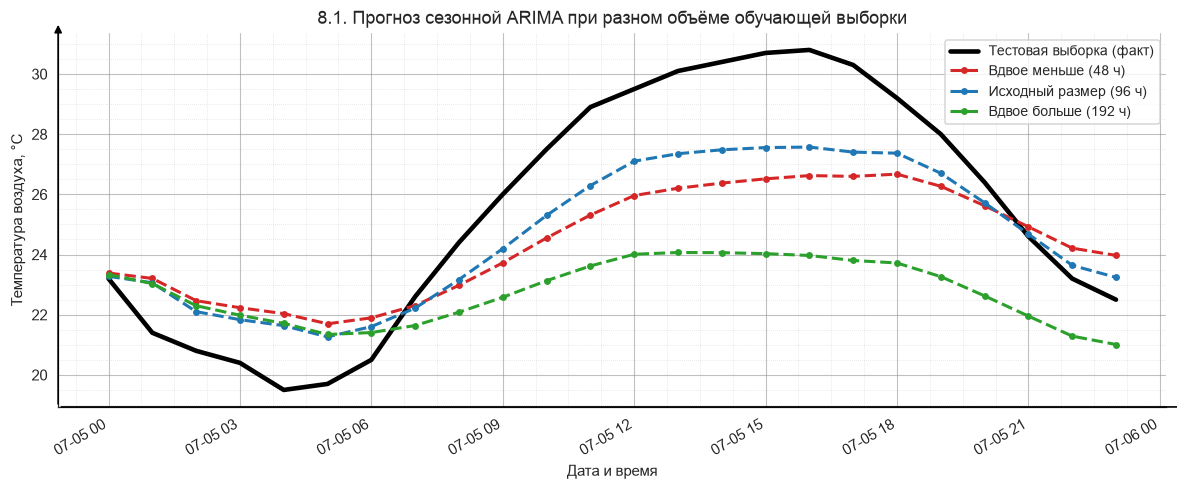

In [24]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(idx_test, y_test_fixed, color="black", lw=3, label="Тестовая выборка (факт)")
for (name, pred), color in zip(size_preds.items(), ["tab:red", "tab:blue", "tab:green"]):
    ax.plot(idx_test, pred, lw=2, ls="--", marker="o", ms=3.5, color=color, label=name)
style_axes(ax, "Дата и время", "Температура воздуха, °C",
           "8.1. Прогноз сезонной ARIMA при разном объёме обучающей выборки")
ax.legend(fontsize=9)
fig.autofmt_xdate()
fig.savefig(FIG / "hw2_10_train_size.png")
plt.show()

Результат оказался не тем, которого можно было ожидать: **удвоение обучающей
выборки прогноз не улучшило, а ухудшило**. Лучше всех отработал исходный объём
в четверо суток, вариант с сокращением вдвое занял промежуточное место.

Зависимость немонотонна, и обе её ветви объясняются по-разному.

*Слева* (48 часов) сказывается нехватка данных: сезонной ARIMA нужно оценить
коэффициент при значении ряда сутки назад, а двое суток дают для этого всего
один повтор цикла — оценка получается шумной.

*Справа* (192 часа) работает противоположная причина — **нестационарность
ряда**. Распечатка средних уровней показывает, что происходит: за неделю до
теста было заметно прохладнее, чем в тестовые сутки. Модель ARIMA считает ряд
стационарным и тянет прогноз к среднему всей обучающей выборки, а чем глубже
история, тем сильнее это среднее занижено относительно текущей обстановки.
Лишние данные описывают уже другую синоптическую ситуацию и вредят.

Вывод, важный для практики: **для краткосрочного прогноза объём истории нужно
не максимизировать, а согласовывать с характерным временем изменения условий**.
Оптимум здесь — несколько суток: достаточно повторов цикла, чтобы оценить
сезонный коэффициент, и достаточно свежие данные, чтобы описывать нынешнюю
погоду. Это ровно та ситуация, в которой «больше данных» не означает «лучше
модель».

### 8.2. Усложнение моделей: предыдущее значение искомого параметра как регрессор

По условию модель на каждом шаге дополняется предыдущим значением искомого
параметра, причём на горизонте прогноза это **расчётное значение предыдущего
шага**, а не фактическое. Это авторегрессионная постановка: прошлые значения
зависимой переменной выступают в роли регрессоров.

Строим три варианта, наращивая глубину памяти, и прогоняем каждый рекурсивно на
все 24 шага функцией `recursive_forecast` из `hw2_utils.py`.

In [26]:
lag_rows = []
lag_preds = {}

for n_lags in [1, 3, 24]:
    X_lag, y_lag = make_lag_matrix(y_train, n_lags)

    model = LinearRegression().fit(X_lag, y_lag)
    pred = recursive_forecast(model, y_train, HORIZON, n_lags)
    lag_preds[f"МНК, {n_lags} предыдущих значений"] = pred
    lag_rows.append({"Модель": "МНК по лагам", "Лагов": n_lags,
                     **metrics_row(y_test, pred)})

    # Тот же набор лагов, но методом SVR.
    sx = StandardScaler().fit(X_lag)
    svr = SVR(kernel="rbf", C=C_BEST, epsilon=EPS_BEST).fit(sx.transform(X_lag), y_lag)
    pred_s = recursive_forecast(svr, y_train, HORIZON, n_lags, scaler=sx)
    lag_preds[f"SVR, {n_lags} предыдущих значений"] = pred_s
    lag_rows.append({"Модель": "SVR по лагам", "Лагов": n_lags,
                     **metrics_row(y_test, pred_s)})

lag_table = pd.DataFrame(lag_rows).sort_values("MAE").reset_index(drop=True)
lag_table.round(3)

,Модель,Лагов,MAE,RMSE,R2
0,МНК по лагам,24,2.639,3.046,0.391
1,SVR по лагам,24,3.482,4.223,-0.172
2,МНК по лагам,1,3.637,4.189,-0.153
3,МНК по лагам,3,4.168,5.140,-0.735
4,SVR по лагам,1,4.259,5.201,-0.777
5,SVR по лагам,3,4.380,5.341,-0.873


МНК, 24 лага + влажность: {'MAE': 2.399, 'RMSE': 2.586, 'R2': 0.561}


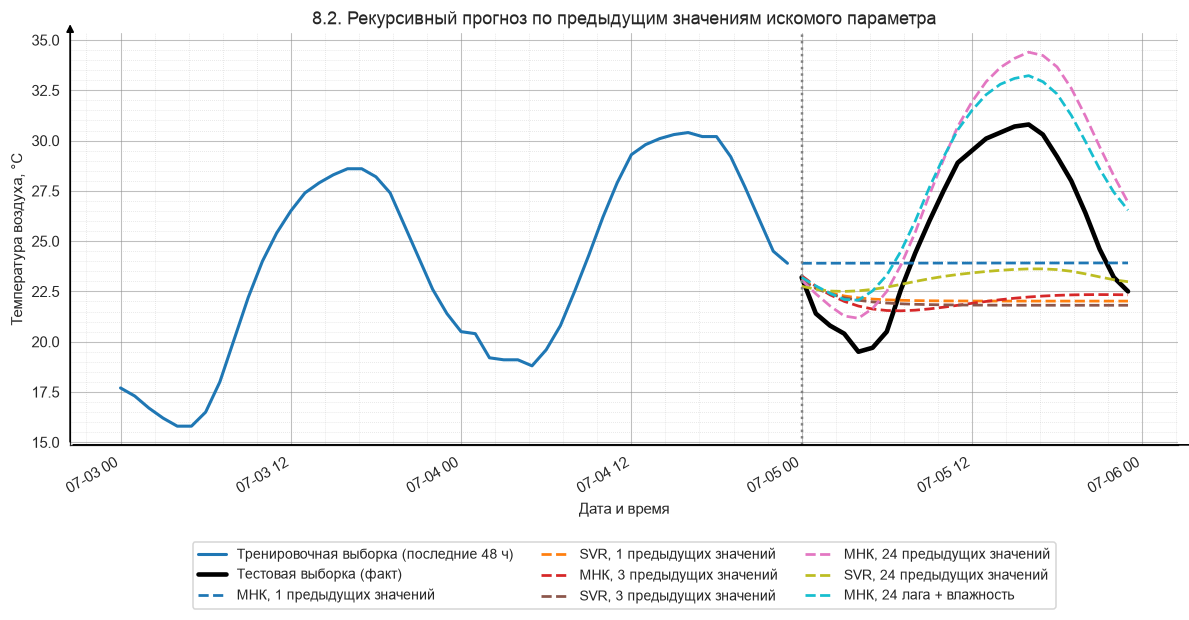

In [26]:
# Вариант с двумя параметрами: лаги температуры + прогноз влажности на шаг.
X_lag24, y_lag24 = make_lag_matrix(y_train, 24)
hum_aligned = hum_train[24:].reshape(-1, 1)        # влажность в момент отклика
X_exog = np.c_[X_lag24, hum_aligned]

model_exog = LinearRegression().fit(X_exog, y_lag24)
pred_exog = recursive_forecast_exog(model_exog, y_train, hum_future, n_lags=24)
lag_preds["МНК, 24 лага + влажность"] = pred_exog
print("МНК, 24 лага + влажность:",
      {k: round(v, 3) for k, v in metrics_row(y_test, pred_exog).items()})

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(idx_train[-48:], y_train[-48:], color="tab:blue", lw=2,
        label="Тренировочная выборка (последние 48 ч)")
ax.plot(idx_test, y_test, color="black", lw=3, label="Тестовая выборка (факт)")
for (name, pred), color in zip(lag_preds.items(), plt.cm.tab10(np.linspace(0, 1, len(lag_preds)))):
    ax.plot(idx_test, pred, lw=1.8, ls="--", color=color, label=name)
ax.axvline(idx_test[0], color="grey", ls=":", lw=1.6)
style_axes(ax, "Дата и время", "Температура воздуха, °C",
           "8.2. Рекурсивный прогноз по предыдущим значениям искомого параметра")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=9, ncol=3)
fig.autofmt_xdate()
fig.savefig(FIG / "hw2_11_recursive.png")
plt.show()

Результат этого опыта — самый показательный во всей работе.

**Один лаг** превращает модель в почти тождественное отображение: лучший способ
предсказать следующий час — взять текущее значение. На одном шаге это отличный
прогноз, но при рекурсии ошибка накапливается, и прогноз плавно сползает к
константе.

**Три лага** ведут себя так же: три последних часа описывают локальный тренд,
которого хватает на несколько шагов вперёд и не хватает на сутки.

**Двадцать четыре лага** — качественный скачок. В наборе регрессоров появляется
значение ровно сутки назад, то есть та же информация, на которой работает
сезонная ARIMA, и модель начинает воспроизводить форму суточного хода. Обычный
МНК по лагам оказывается сопоставим со специализированной моделью временного
ряда — потому что у них одна и та же информационная основа.

Общий вывод: **накопление ошибки при рекурсии ограничивает горизонт, но
решающим остаётся состав регрессоров**. Модель, среди входов которой есть
значение через период цикла, держит горизонт в сутки; модель без него теряет
информацию за несколько шагов независимо от того, каким методом она обучена.

---
## Пункт 5. Итоговые выводы

### Выполнение пунктов задания

| Пункт | Раздел | Результат |
|---|---|---|
| 1. 100+ значений, разбиение 80/20 | 1 | 120 часов: 96 обучение, 24 тест |
| 1а. ARIMA | 2 | Порядок по AIC, сезонный и несезонный варианты |
| 1б. k-NN / скользящее среднее | 3 | k подобран по внутренней проверке |
| 2. МНК $y=c_0+c_1x$ и SVR | 4 | Коэффициенты проверены формулой $c = (A^TA)^{-1}A^Ty$ |
| 3. Две переменные $y=c_0+c_1x_1+c_2x_2$ | 5 | Второй параметр — влажность, на горизонт прогнозируется |
| 4. Графики всех моделей с выборками | 2—8 | 11 рисунков `hw2_*.png` |
| 5. MAE, RMSE, выводы | 6, 9 | Сводные таблицы и сравнение |
| Доп. +1: свой ряд, Lasso, PLS, R² | 1, 7 | 5 регрессоров, подбор alpha и компонент |
| Доп. +2: размер выборки, рекурсия по лагам | 8 | Три объёма обучения, лаги 1/3/24 |

### Содержательные результаты

1. **Качество прогноза определяется не сложностью метода, а доступом модели к
   информации о суточном цикле.** Сезонная ARIMA, МНК по 24 лагам и
   двухпараметрические модели с влажностью работают на горизонте суток; их
   несезонные аналоги — нет, включая нелинейный SVR.

2. **Экстраполяция принципиально отличается от интерполяции.** SVR с RBF-ядром
   хорошо описывает обучающий интервал и вырождается в константу сразу за его
   границей: ядро измеряет близость к опорным векторам, а точки прогноза
   далеки от всех обучающих.

3. **Рекурсивная схема накапливает ошибку.** Скользящее среднее демонстрирует
   это в чистом виде: через k шагов в окне не остаётся реальных наблюдений,
   и прогноз застывает. Величина k на это не влияет.

4. **Многопараметрическая модель требует прогноза каждого параметра.**
   Значения влажности и давления на горизонте неизвестны, и подстановка их
   прогнозов переносит часть ошибки в итоговый результат — цена, которую
   всё же окупает информация о фазе цикла.

5. **$R^2$ и MAE отвечают на разные вопросы.** MAE и RMSE дают величину ошибки
   в градусах, $R^2$ — сравнение с прогнозом-средним. Модель с умеренным MAE
   может иметь $R^2 \le 0$, то есть не давать ничего сверх константы.

6. **Больше данных не значит лучше прогноз.** Удвоение обучающей выборки
   ухудшило результат: ряд нестационарен, и данные недельной давности
   описывают уже другую синоптическую обстановку, занижая средний уровень, к
   которому ARIMA тянет прогноз. Оптимум — несколько суток.

### Признаки недообучения и переобучения

Обе крайности в работе наблюдались явно.

**Недообучение** — однопараметрический МНК: прямая не способна выразить
суточные колебания ни на обучении, ни на тесте, то есть модель не проходит
проверку на адекватность и обладает плохими прогностическими свойствами.

**Переобучение** — SVR на времени: в таблице подбора гиперпараметров ошибка на
внутренней проверке монотонно растёт с увеличением C, хотя обучающие точки при
этом описываются всё точнее. Проверка проходит на
тренировочных данных и не проходит на новых. Показательно, что подбор выбрал
наименьшее из рассмотренных значений C — на экстраполяции выгоднее самая
сглаженная версия модели.